# **Comparative Implementation of Machine Learning Regression Algorithms**

**Install libraries**

In [13]:
!pip install -q xgboost scikit-learn pandas numpy matplotlib

**Import libraries**

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


**Load dataset**

In [15]:
# Load California Housing Dataset

housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

print("Dataset Loaded Successfully!")
print("Features:", X.shape)
print("Target:", y.shape)

print("\nFirst 5 rows:")
display(X.head())

print("\nTarget values:")
display(y.head())

print("\nDataset Information:")
print(X.info())

print("\nMissing Values:")
print(X.isnull().sum())

Dataset Loaded Successfully!
Features: (20640, 8)
Target: (20640,)

First 5 rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25



Target values:


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB
None

Missing Values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


**Split dataset (80:20)**

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training percentage: 80%")
print("Testing percentage: 20%")

Training samples: 16512
Testing samples: 4128
Training percentage: 80%
Testing percentage: 20%


**Data preprocessing**

In [17]:
# Preprocessing for Linear Regression, Neural Network and KNN

scaled_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for tree-based algorithms

tree_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

print("Data preprocessing completed!")

Data preprocessing completed!


**Define six regression models**

In [18]:
models = {

    "Linear Regression": Pipeline([
        ("preprocessing", scaled_preprocessor),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessing", tree_preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=12,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessing", tree_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Neural Network": Pipeline([
        ("preprocessing", scaled_preprocessor),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=True,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessing", tree_preprocessor),
        ("model", XGBRegressor(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessing", scaled_preprocessor),
        ("model", KNeighborsRegressor(
            n_neighbors=7,
            weights="distance",
            n_jobs=-1
        ))
    ])
}

print("All six regression models are ready!")

All six regression models are ready!


**Train all six models**

In [19]:
results = []
predictions = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))

print("\nAll models trained successfully!")


Training: Linear Regression
MAE: 0.5332
MSE: 0.5559
RMSE: 0.7456
R2 Score: 0.5758

Training: Decision Tree
MAE: 0.4133
MSE: 0.3883
RMSE: 0.6232
R2 Score: 0.7037

Training: Random Forest
MAE: 0.326
MSE: 0.254
RMSE: 0.504
R2 Score: 0.8061

Training: Neural Network
MAE: 0.3533
MSE: 0.2745
RMSE: 0.5239
R2 Score: 0.7905

Training: XGBoost
MAE: 0.2898
MSE: 0.197
RMSE: 0.4438
R2 Score: 0.8497

Training: KNN
MAE: 0.4412
MSE: 0.4237
RMSE: 0.6509
R2 Score: 0.6767

All models trained successfully!


**Comparative performance table**

In [20]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("COMPARATIVE PERFORMANCE OF SIX REGRESSION ALGORITHMS")

display(
    results_df.style.format({
        "MAE": "{:.4f}",
        "MSE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2 Score": "{:.4f}"
    }).highlight_min(
        subset=["MAE", "MSE", "RMSE"],
        color="lightgreen"
    ).highlight_max(
        subset=["R2 Score"],
        color="lightgreen"
    )
)

COMPARATIVE PERFORMANCE OF SIX REGRESSION ALGORITHMS


,Algorithm,MAE,MSE,RMSE,R2 Score
0,XGBoost,0.2898,0.1970,0.4438,0.8497
1,Random Forest,0.3260,0.2540,0.5040,0.8061
2,Neural Network,0.3533,0.2745,0.5239,0.7905
3,Decision Tree,0.4133,0.3883,0.6232,0.7037
4,KNN,0.4412,0.4237,0.6509,0.6767
5,Linear Regression,0.5332,0.5559,0.7456,0.5758


**Actual vs Predicted graphs**

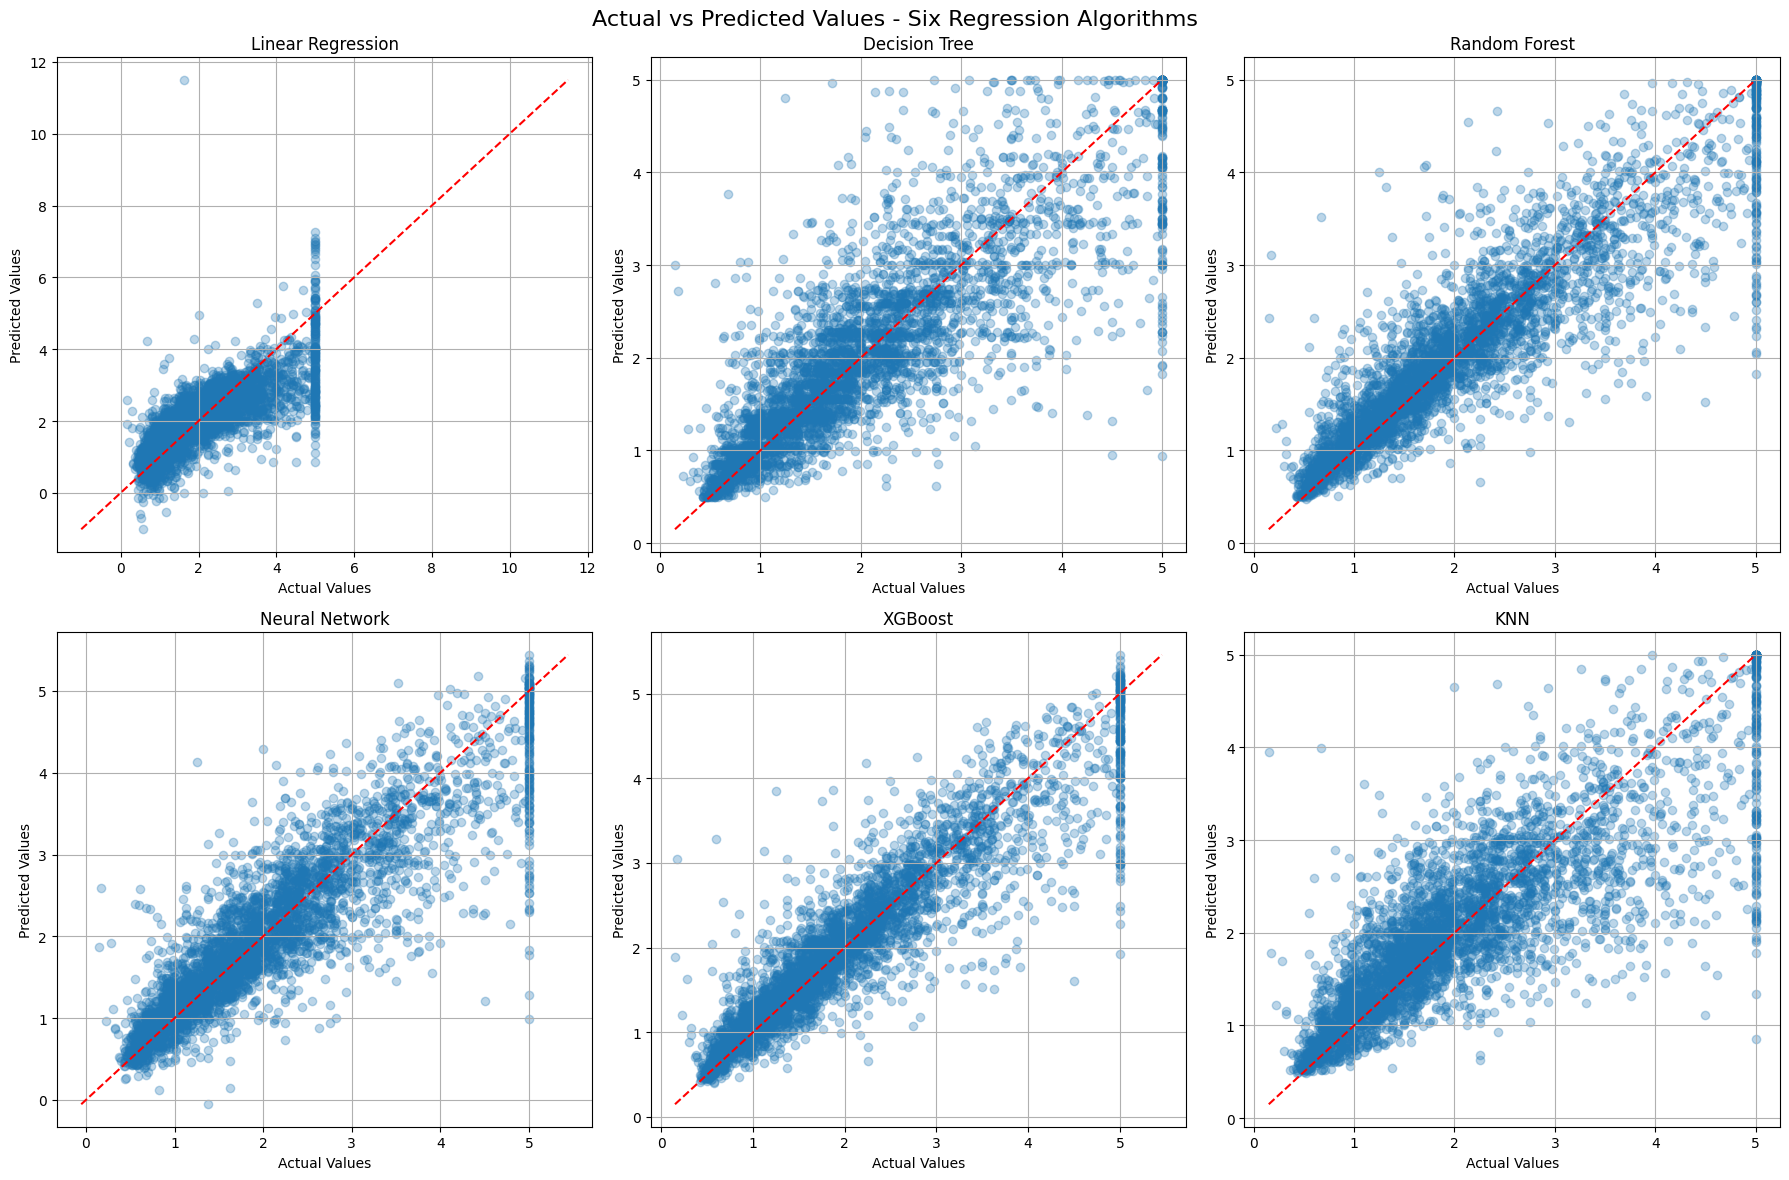

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.3
    )

    minimum = min(y_test.min(), y_pred.min())
    maximum = max(y_test.max(), y_pred.max())

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.grid(True)

plt.suptitle(
    "Actual vs Predicted Values - Six Regression Algorithms",
    fontsize=16
)

plt.tight_layout()
plt.show()

**MAE and RMSE comparison**

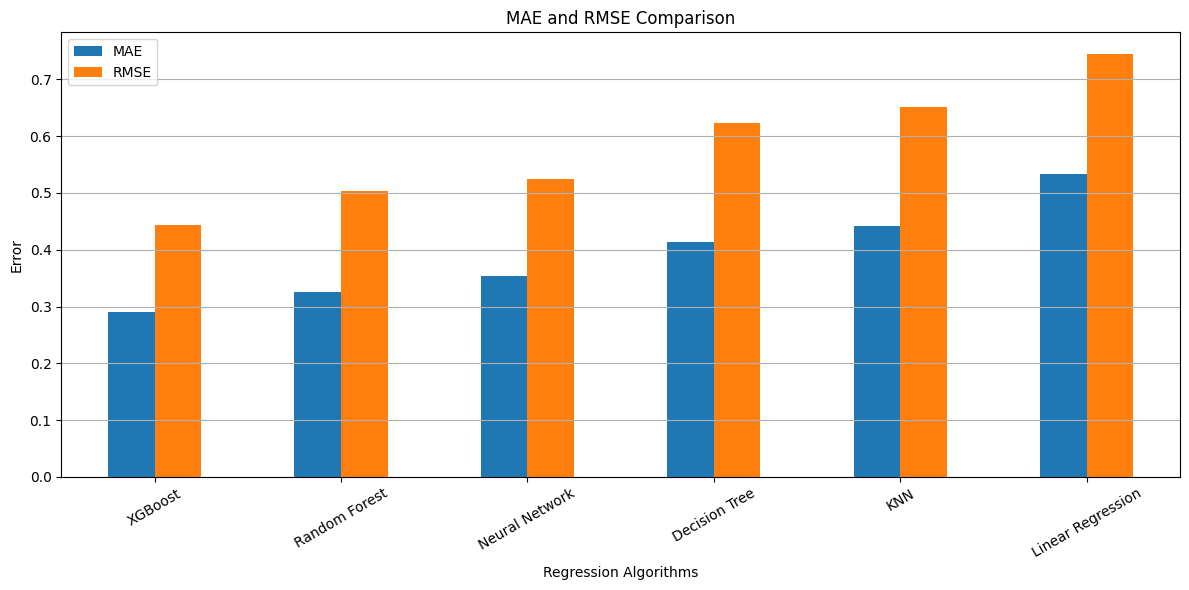

In [22]:
results_df.set_index("Algorithm")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("MAE and RMSE Comparison")
plt.xlabel("Regression Algorithms")
plt.ylabel("Error")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.legend()
plt.tight_layout()
plt.show()

**R² Score comparison**

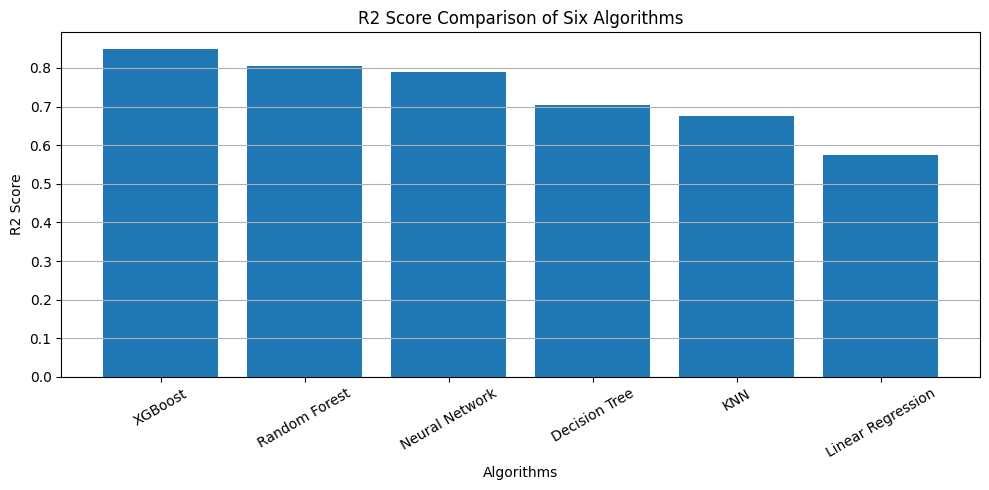

In [23]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["R2 Score"]
)

plt.title("R2 Score Comparison of Six Algorithms")
plt.xlabel("Algorithms")
plt.ylabel("R2 Score")

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.tight_layout()
plt.show()

**Identify best-performing algorithm**

In [24]:
best_model = results_df.iloc[0]

print("BEST PERFORMING REGRESSION ALGORITHM")
print("------------------------------------")

print("Algorithm:", best_model["Algorithm"])
print("MAE:", round(best_model["MAE"], 4))
print("MSE:", round(best_model["MSE"], 4))
print("RMSE:", round(best_model["RMSE"], 4))
print("R2 Score:", round(best_model["R2 Score"], 4))

print("\nConclusion:")
print(
    best_model["Algorithm"],
    "is the best model based on the lowest RMSE "
    "among the six tested algorithms."
)

BEST PERFORMING REGRESSION ALGORITHM
------------------------------------
Algorithm: XGBoost
MAE: 0.2898
MSE: 0.197
RMSE: 0.4438
R2 Score: 0.8497

Conclusion:
XGBoost is the best model based on the lowest RMSE among the six tested algorithms.
